# DataCo-RecEngine | Coding Exercises
**Instructions:** Complete each empty code cell yourself. Python exercises only. No solutions included.

### Step 0.1 — Verify your environment
- Display the Python version.
- Import pandas, numpy, and scikit-learn.
- Print their versions.

In [1]:
import sys
import pandas as pd
import numpy as np
import sklearn

print("Python version:", sys.version)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)

Python version: 3.12.16 (main, Oct 26 2026, 14:08:45) [Clang 23.1.3 ]
Pandas version: 3.1.1
NumPy version: 2.5.5
Scikit-learn version: 1.9.1


### Step 0.2 — Load the original CSV
- Load `../data/raw/PJME_hourly.csv` with pandas (notebook runs from `notebooks/`).
- Display the first five rows and dataset shape.
- Do not overwrite the original file.

In [3]:
import pandas as pd

CSV_PATH = "/home/mestry/Documents/youcode/DataCo-RecEngine/data/raw/pjme-hourly-6951852bda3c4588058217-6b0360cfa260b742484012.csv"
df = pd.read_csv(CSV_PATH)

display(df.head())

print("Dataset shape:", df.shape)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

,Datetime,PJME_MW
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0
3,2002-12-31 04:00:00,24393.0
4,2002-12-31 05:00:00,24860.0


Dataset shape: (145366, 2)
Rows: 145366
Columns: 2


### Step 0.3 — Audit the columns
- Display column names and data types.
- Count missing values in each column.
- Count fully duplicated rows.
- Check whether `PJME_MW` contains negative or zero values.

In [4]:

print(df.columns.tolist())


print(df.dtypes)


print(df.isnull().sum())


print("Duplicate rows:", df.duplicated().sum())

print("Negative values:", (df["PJME_MW"] < 0).sum())
print("Zero values:", (df["PJME_MW"] == 0).sum())

['Datetime', 'PJME_MW']
Datetime        str
PJME_MW     float64
dtype: object
Datetime    0
PJME_MW     0
dtype: int64
Duplicate rows: 0
Negative values: 0
Zero values: 0


### Step 0.4 — Validate the timestamps
- Convert `Datetime` to a datetime type.
- Count invalid dates and duplicate timestamps.
- Sort the dataset chronologically.
- Display the earliest and latest dates.

In [5]:

df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")


print("Invalid dates:", df["Datetime"].isna().sum())

print("Duplicate timestamps:", df["Datetime"].duplicated().sum())

df = df.sort_values("Datetime").reset_index(drop=True)

print("Earliest date:", df["Datetime"].min())
print("Latest date:", df["Datetime"].max())

Invalid dates: 0
Duplicate timestamps: 4
Earliest date: 2002-01-01 01:00:00
Latest date: 2018-08-03 00:00:00


### Step 0.5 — Audit the hourly frequency
- Calculate the difference between consecutive timestamps.
- Count intervals different from one hour.
- List missing hourly timestamps over the observed date range.
- Investigate duplicate or missing hours before choosing a repair method; remember daylight-saving-time effects.

In [10]:

time_diff = df["Datetime"].diff()

non_hourly = (time_diff.dropna() != pd.Timedelta(hours=1)).sum()

print("Non-hourly intervals:", non_hourly)

duplicates = df["Datetime"].duplicated().sum()
print("Duplicate timestamps:", duplicates)

expected_hours = pd.date_range(
    start=df["Datetime"].min(),
    end=df["Datetime"].max(),
    freq="h"
)

missing_hours = expected_hours.difference(df["Datetime"])

print("Missing hours:", len(missing_hours))

Non-hourly intervals: 34
Duplicate timestamps: 4
Missing hours: 30


### Step 0.6 — Explore electricity demand
- Display descriptive statistics for `PJME_MW`.
- Plot electricity demand over time.
- Plot average demand by hour and day of week.
- Identify unusual values without changing the raw CSV.

,Datetime,PJME_MW,Hour,DayOfWeek
count,145366,145366.000000,145366.000000,145366.000000
mean,2010-04-18 03:25:25.999202,32080.222831,11.501596,2.999003
min,2002-01-01 01:00:00,14544.000000,0.000000,0.000000
25%,2006-02-23 14:15:00,27573.000000,6.000000,1.000000
50%,2010-04-18 04:30:00,31421.000000,12.000000,3.000000
75%,2014-06-10 18:45:00,35650.000000,18.000000,5.000000
max,2018-08-03 00:00:00,62009.000000,23.000000,6.000000
std,NaN,6464.012166,6.921794,1.999503


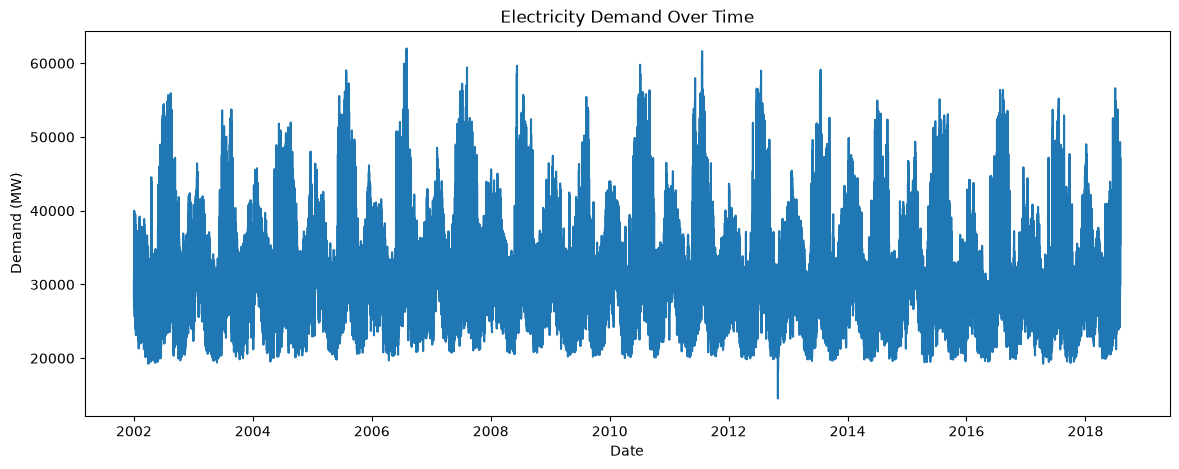

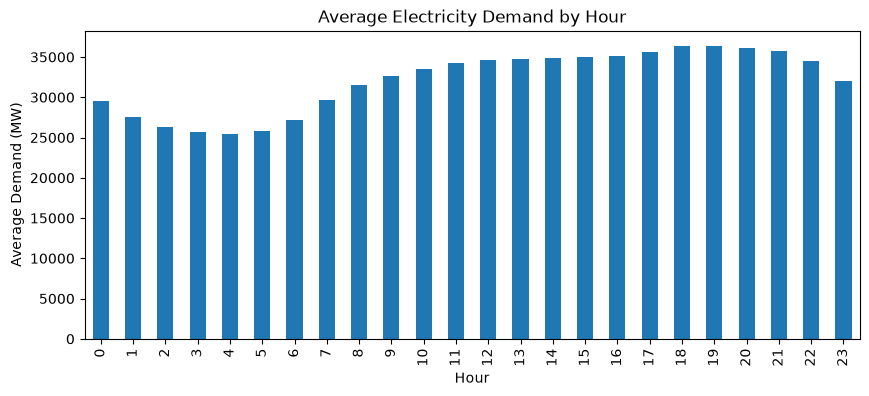

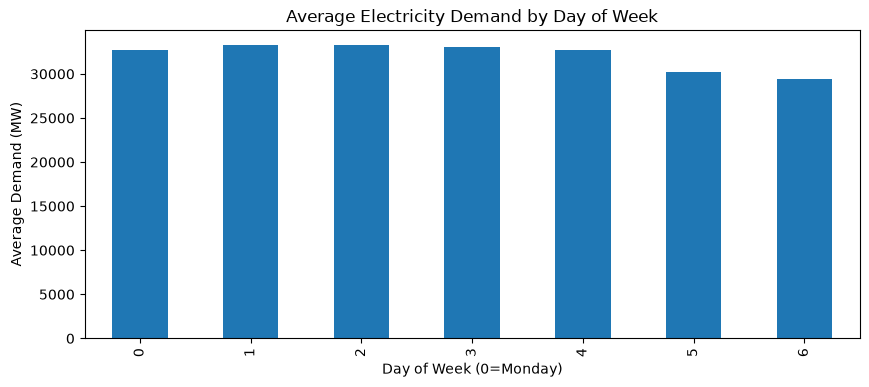

Potential outliers: 3455


,Datetime,PJME_MW,Hour,DayOfWeek
3878,2002-06-11 16:00:00,48426.0,16,1
3879,2002-06-11 17:00:00,48968.0,17,1
3880,2002-06-11 18:00:00,48565.0,18,1
3901,2002-06-12 15:00:00,47852.0,15,2
4187,2002-06-24 13:00:00,48937.0,13,0


In [13]:
import matplotlib.pyplot as plt


display(df.describe())

plt.figure(figsize=(14, 5))
plt.plot(df["Datetime"], df["PJME_MW"])
plt.title("Electricity Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Demand (MW)")
plt.show()

df["Hour"] = df["Datetime"].dt.hour

hourly_average = df.groupby("Hour")["PJME_MW"].mean()

plt.figure(figsize=(10, 4))
hourly_average.plot(kind="bar")
plt.title("Average Electricity Demand by Hour")
plt.xlabel("Hour")
plt.ylabel("Average Demand (MW)")
plt.show()


df["DayOfWeek"] = df["Datetime"].dt.day_of_week

daily_average = df.groupby("DayOfWeek")["PJME_MW"].mean()

plt.figure(figsize=(10, 4))
daily_average.plot(kind="bar")
plt.title("Average Electricity Demand by Day of Week")
plt.xlabel("Day of Week (0=Monday)")
plt.ylabel("Average Demand (MW)")
plt.show()


Q1 = df["PJME_MW"].quantile(0.25)
Q3 = df["PJME_MW"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["PJME_MW"] < lower) |
    (df["PJME_MW"] > upper)
]

print("Potential outliers:", len(outliers))
display(outliers.head())

### Step 0.7 — Save an audit report
- Create a compact dictionary or DataFrame of quality checks.
- Export the audit results under `../reports/`.
- Record the row count, date range, missing data, duplicate timestamps, and frequency issues.

In [14]:
from pathlib import Path

reports_path = Path("../reports")
reports_path.mkdir(parents=True, exist_ok=True)

audit = {
    "Total Rows": len(df),
    "Total Columns": 2,
    "Earliest Date": str(df["Datetime"].min()),
    "Latest Date": str(df["Datetime"].max()),
    "Missing Datetime": df["Datetime"].isna().sum(),
    "Missing PJME_MW": df["PJME_MW"].isna().sum(),
    "Duplicate Timestamps": df["Datetime"].duplicated().sum(),
    "Non-Hourly Intervals": non_hourly,
    "Missing Hourly Timestamps": len(missing_hours),
    "Negative Consumption": (df["PJME_MW"] < 0).sum(),
    "Zero Consumption": (df["PJME_MW"] == 0).sum(),
    "Potential Outliers": len(outliers)
}

audit_df = pd.DataFrame(
    list(audit.items()),
    columns=["Check", "Result"]
)

audit_df.to_csv(reports_path / "data_quality_audit.csv", index=False)

display(audit_df)

print("Audit report saved successfully!")

,Check,Result
0,Total Rows,145366
1,Total Columns,2
2,Earliest Date,2002-01-01 01:00:00
3,Latest Date,2018-08-03 00:00:00
4,Missing Datetime,0
5,Missing PJME_MW,0
6,Duplicate Timestamps,4
7,Non-Hourly Intervals,34
8,Missing Hourly Timestamps,30
9,Negative Consumption,0


Audit report saved successfully!


### Step 1 — Validate the source file for ingestion
- Check that the original CSV exists and has the expected two columns: `Datetime`, `PJME_MW`.
- Validate values and parseability; report any invalid records.
- Compute a SHA-256 checksum of the original file.
- Do not modify the source CSV.

### Step 2 — Prepare a reproducible data sample
- Create a small, representative CSV sample for testing.
- Save it in `../data/sample/`, not in `../data/raw/`.
- Verify that the sample can be reloaded with the same columns.

### Step 3 — Time-based feature engineering
- Create `Hour`, `DayOfWeek`, `Month`, `Quarter`, `Year`, and `DayOfYear`.
- Add useful cyclical time features if you choose.
- Preserve chronological order.

### Step 4 — Define one-hour-ahead forecasting
- Use a one-hour-ahead forecasting horizon (t+1).
- Create historical demand features (for example, lag 1 hour and lag 24 hours) that are available at prediction time.
- Ensure the target represents the following hour, and avoid using future values as inputs.
- Remove rows made invalid by lag/target shifting.

### Step 5 — Prepare training and test sets
- Choose input features and the target.
- Split chronologically: first 80% for training, final 20% for testing.
- Do not shuffle.
- Print the date ranges and shapes of both splits.

### Step 6 — Build a baseline forecast
- Make a simple baseline prediction using the last observed demand.
- Calculate MAE and RMSE on the test set.
- Save baseline metrics for comparison.

Lower bound: 15457.5
Upper bound: 47765.5
Potential outliers: 3455


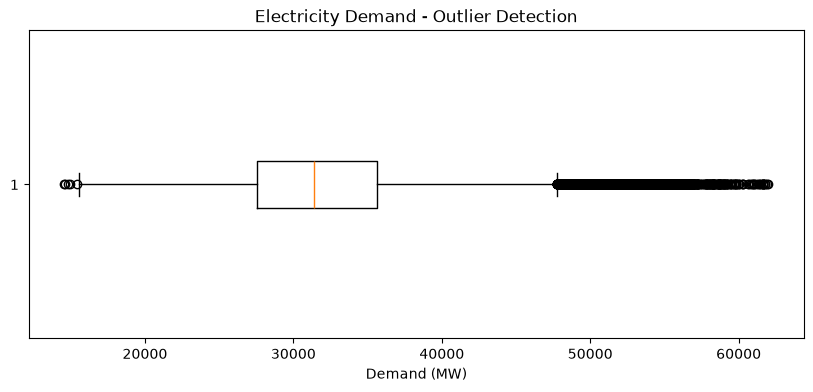

Original: (145366, 4)

Copy: (145366, 2)

Data types:
Datetime    datetime64[us]
PJME_MW            float64
dtype: object

Missing values:
Datetime    0
PJME_MW     0
dtype: int64

Duplicate rows: 0

Duplicate timestamps: 4


,Datetime,PJME_MW
112487,2014-11-02 02:00:00,23755.0
112488,2014-11-02 02:00:00,22935.0
121223,2015-11-01 02:00:00,21171.0
121224,2015-11-01 02:00:00,21567.0
130127,2016-11-06 02:00:00,20795.0
130128,2016-11-06 02:00:00,21692.0
138863,2017-11-05 02:00:00,21236.0
138864,2017-11-05 02:00:00,20666.0


Dataset saved!
Final shape: (145366, 2)


In [26]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

df_clean = df[["Datetime", "PJME_MW"]].copy()

df_clean["Datetime"] = pd.to_datetime(
    df_clean["Datetime"],
    errors="coerce"
)

df_clean["PJME_MW"] = pd.to_numeric(
    df_clean["PJME_MW"],
    errors="coerce"
)

Q1 = df_clean["PJME_MW"].quantile(0.25)
Q3 = df_clean["PJME_MW"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df_clean[
    (df_clean["PJME_MW"] < lower) |
    (df_clean["PJME_MW"] > upper)
]

print("Lower bound:", lower)
print("Upper bound:", upper)
print("Potential outliers:", len(outliers))

plt.figure(figsize=(10, 4))
plt.boxplot(
    df_clean["PJME_MW"].dropna(),
    orientation="horizontal"
)
plt.title("Electricity Demand - Outlier Detection")
plt.xlabel("Demand (MW)")
plt.show()

df_clean = df_clean.sort_values("Datetime").reset_index(drop=True)

output_path = Path("../data/processed")
output_path.mkdir(parents=True, exist_ok=True)

df_clean.to_csv(
    output_path / "PJME_cleaned.csv",
    index=False
)

print("Original:", df.shape)
print("\nCopy:", df_clean.shape)

print("\nData types:")
print(df_clean.dtypes)

print("\nMissing values:")
print(df_clean.isna().sum())

print("\nDuplicate rows:", df_clean.duplicated().sum())
print("\nDuplicate timestamps:", df_clean["Datetime"].duplicated().sum())

display(
    df_clean[
        df_clean["Datetime"].duplicated(keep=False)
    ]
)

print("Dataset saved!")
print("Final shape:", df_clean.shape)

### Step 7 — Train a regression model
- Choose a suitable scikit-learn regression model.
- Fit any learned preprocessing using training data only.
- Train on the training set.
- Generate predictions for the test set.

### Step 8 — Evaluate the model
- Calculate MAE, RMSE, and optionally R².
- Compare the model against your baseline.
- Plot actual vs predicted demand and inspect errors.
- Avoid classification metrics such as accuracy or F1.

### Step 9 — Validate on time-series folds
- Use a chronological cross-validation method such as TimeSeriesSplit.
- Repeat model training and evaluation without leakage.
- Summarize average validation errors.

### Step 10 — Save local artifacts
- Save the fitted model and required preprocessing artifacts in `../models/`.
- Save final metrics and experiment notes in `../reports/`.
- Keep large or sensitive generated artifacts out of Git as appropriate.

### Step 11 — Test inference
- Load the saved model.
- Build one example input using only information available at prediction time.
- Predict the next hour of electricity demand.
- Check that the result is numeric and finite.

### Step 12 — Add automated tests
- Write tests for date parsing and required columns.
- Test feature creation and chronological splitting.
- Test that predictions do not use future target values.
- Move reusable code into `src/` and tests into `tests/`.

### Azure integration coding tasks (after subscription access)

### Step 13 — Azure authentication check
- Authenticate with the supported Azure identity mechanism.
- Programmatically check the configured subscription, resource group, and North Europe location.
- Do not put secrets in code or notebook outputs.

### Step 14 — Azure ML assets
- Define the datastore connection to the Data Lake `raw/` path.
- Register the intended CSV data asset.
- Verify the asset can be accessed from the Azure ML workspace.

### Step 15 — Azure ML compute and jobs
- Create or verify CPU compute using `Standard_DS11_v2`.
- Set autoscale minimum to 0 and maximum to 1.
- Submit a small training job only after reviewing cost and quota.
- Record job information and evaluation metrics.

### Step 16 — Save a reproducibility checkpoint
- Export non-secret Azure resource configuration and relevant job metadata.
- Back up pipeline definitions and recoverable model/data artifacts locally.
- Verify the checkpoint files exist and can be read.
- Never export tokens, credentials, or personal data unnecessarily.